In [1]:
# Mengimpor modul ekstraksi fitur dan partisi data
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
print("Pustaka ekstraksi fitur dan splitting berhasil dimuat.")

Pustaka ekstraksi fitur dan splitting berhasil dimuat.


In [2]:
# Memuat dataset ulasan dan aspek sentimen
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

# Menggunakan kolom cleaned_text jika ada, atau membuat jika belum ada
if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

# Menggabungkan data ulasan dengan label sentimen dan aspek
df_merged = pd.merge(
    df_aspects[['id', 'review_id', 'cafe_id', 'aspect', 'sentiment', 'confidence']],
    df_reviews[['id', 'cleaned_text', 'rating', 'likes']],
    left_on='review_id',
    right_on='id',
    suffixes=('_aspect', '_review')
)

# Menghapus entri dengan ulasan kosong setelah pembersihan
df_dataset = df_merged[df_merged['cleaned_text'].str.len() > 3].copy().reset_index(drop=True)

print(f"Total pasangan ulasan-aspek yang valid: {len(df_dataset):,} baris")
print("\nDistribusi Label Sentimen Target:")
print(df_dataset['sentiment'].value_counts())
print(f"\nDistribusi Proporsi (%):\n{(df_dataset['sentiment'].value_counts(normalize=True)*100).round(2)}")

Total pasangan ulasan-aspek yang valid: 9,257 baris

Distribusi Label Sentimen Target:
sentiment
positive    6156
neutral     2716
negative     385
Name: count, dtype: int64

Distribusi Proporsi (%):
sentiment
positive    66.50
neutral     29.34
negative     4.16
Name: proportion, dtype: float64


In [3]:
# Ekstraksi fitur teks menggunakan CountVectorizer
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_features=1000
)

X_bow = bow_vectorizer.fit_transform(df_dataset['cleaned_text'])
vocab_bow = bow_vectorizer.get_feature_names_out()

print(f"Dimensi Matriks Fitur Bag-of-Words : {X_bow.shape} (baris dokumen x fitur kata)")
print(f"Jumlah Kosakata (Vocabulary Size)  : {len(vocab_bow)}")
print(f"Tingkat Kepadatan (Sparsity)       : {(X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])) * 100:.2f}% data non-zero")

# Top 10 kata dengan frekuensi total tertinggi dalam korpus
total_word_counts = np.array(X_bow.sum(axis=0)).flatten()
top_indices = total_word_counts.argsort()[::-1][:10]
df_top_bow = pd.DataFrame({'Token': vocab_bow[top_indices], 'Total_Frekuensi': total_word_counts[top_indices]})
print("\nTop 10 Token Paling Sering Muncul (BoW):")
print(df_top_bow.to_string(index=False))

Dimensi Matriks Fitur Bag-of-Words : (9257, 1000) (baris dokumen x fitur kata)
Jumlah Kosakata (Vocabulary Size)  : 1000
Tingkat Kepadatan (Sparsity)       : 1.80% data non-zero

Top 10 Token Paling Sering Muncul (BoW):
 Token  Total_Frekuensi
   dan             6349
  enak             4935
    di             3067
nyaman             2939
  yang             2914
  juga             2849
  buat             2832
   nya             2826
tempat             2759
 untuk             2204


In [4]:
# Ekstraksi fitur teks menggunakan TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_features=1000,
    sublinear_tf=True # Menggunakan skala logaritmik 1 + log(tf)
)

X_tfidf = tfidf_vectorizer.fit_transform(df_dataset['cleaned_text'])
vocab_tfidf = tfidf_vectorizer.get_feature_names_out()

print(f"Dimensi Matriks Fitur TF-IDF : {X_tfidf.shape}")
print(f"Tipe Data Matriks             : {type(X_tfidf).__name__} (CSR Sparse Matrix)")

# Menampilkan rata-rata skor TF-IDF tertinggi
avg_tfidf_scores = np.array(X_tfidf.mean(axis=0)).flatten()
top_tfidf_indices = avg_tfidf_scores.argsort()[::-1][:10]
df_top_tfidf = pd.DataFrame({'Token': vocab_tfidf[top_tfidf_indices], 'Rata_Rata_TFIDF': avg_tfidf_scores[top_tfidf_indices].round(4)})
print("\nTop 10 Token dengan Bobot TF-IDF Tertinggi:")
print(df_top_tfidf.to_string(index=False))

Dimensi Matriks Fitur TF-IDF : (9257, 1000)
Tipe Data Matriks             : csr_matrix (CSR Sparse Matrix)

Top 10 Token dengan Bobot TF-IDF Tertinggi:
    Token  Rata_Rata_TFIDF
     enak           0.0620
      dan           0.0505
   nyaman           0.0481
   tempat           0.0403
     buat           0.0366
      nya           0.0352
tempatnya           0.0336
     juga           0.0311
       di           0.0287
  makanan           0.0279


Top 10 Kata Paling Diskriminatif (Chi-Square):
 Token  Chi2_Score
 kotor      183.51
 panas      174.85
  enak      147.27
 mahal      140.90
kurang      136.86
nyaman      107.31
hambar       79.48
mantap       68.40
coffee       66.16
   bau       58.84


<string>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



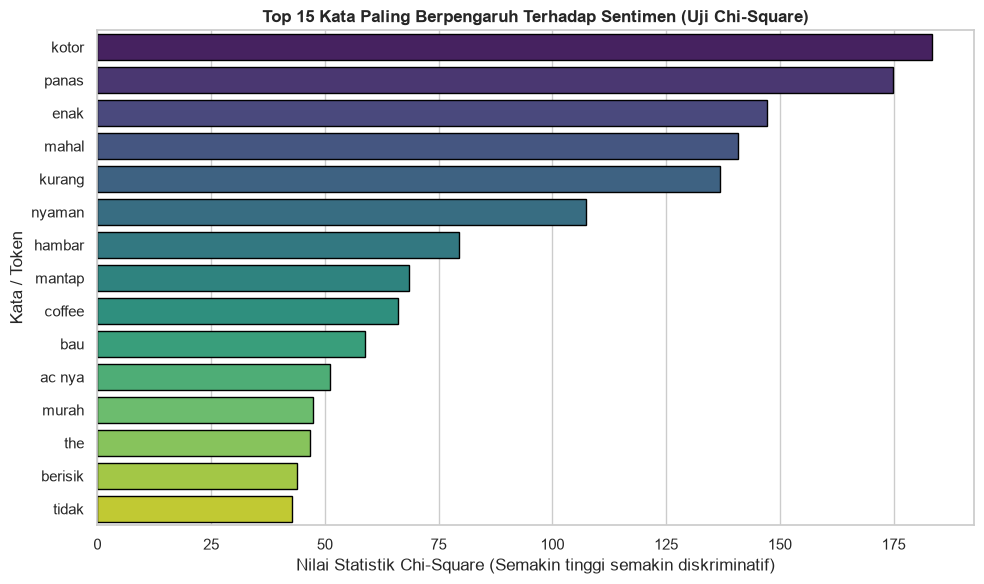

In [5]:
# Menghitung skor Chi-Square terhadap label sentimen
y_sentimen = df_dataset['sentiment']

k_best = 20
selector = SelectKBest(score_func=chi2, k=k_best)
selector.fit(X_tfidf, y_sentimen)

chi2_scores = selector.scores_
top_chi2_idx = np.argsort(chi2_scores)[::-1][:k_best]

df_chi2 = pd.DataFrame({
    'Token': vocab_tfidf[top_chi2_idx],
    'Chi2_Score': chi2_scores[top_chi2_idx].round(2)
})

# Visualisasi Top 15 Fitur Chi-Square
plt.figure(figsize=(10, 6))
sns.barplot(data=df_chi2.head(15), y='Token', x='Chi2_Score', palette='viridis', edgecolor='black')
plt.title('Top 15 Kata Paling Berpengaruh Terhadap Sentimen (Uji Chi-Square)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai Statistik Chi-Square (Semakin tinggi semakin diskriminatif)')
plt.ylabel('Kata / Token')
plt.tight_layout()
plt.show()

print("Top 10 Kata Paling Diskriminatif (Chi-Square):")
print(df_chi2.head(10).to_string(index=False))

In [6]:
# Mengekstrak fitur metadata ulasan
df_dataset['word_count']  = df_dataset['cleaned_text'].apply(lambda x: len(x.split()))
df_dataset['char_length'] = df_dataset['cleaned_text'].apply(len)

meta_cols = ['rating', 'likes', 'word_count', 'char_length']
print("Statistik Deskriptif Fitur Metadata Ulasan:")
print(df_dataset[meta_cols].describe().round(2))

# Korelasi antara rating ulasan dan panjang teks
corr_val = df_dataset['rating'].corr(df_dataset['word_count'])
print(f"\nKorelasi Pearson antara Rating Bintang dan Panjang Ulasan (Word Count): {corr_val:.4f}")

Statistik Deskriptif Fitur Metadata Ulasan:
        rating    likes  word_count  char_length
count  9257.00  9257.00     9257.00      9257.00
mean      4.57     0.05       23.33       144.89
std       1.02     0.30       26.95       166.85
min       1.00     0.00        1.00         4.00
25%       5.00     0.00        8.00        48.00
50%       5.00     0.00       16.00        97.00
75%       5.00     0.00       30.00       187.00
max       5.00     6.00      348.00      2146.00

Korelasi Pearson antara Rating Bintang dan Panjang Ulasan (Word Count): -0.2115


In [7]:
# 1. Random Split (tanpa stratifikasi)
X = df_dataset['cleaned_text']
y = df_dataset['sentiment']

X_train_rnd, X_test_rnd, y_train_rnd, y_test_rnd = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True
)

# 2. Stratified Split (dengan stratifikasi label)
X_train_str, X_test_str, y_train_str, y_test_str = train_test_split(
    X, y, test_size=0.20, random_state=42, shuffle=True, stratify=y
)

# Perbandingan Sebaran Kelas
dist_asli = (y.value_counts(normalize=True) * 100).round(2)
dist_rnd  = (y_test_rnd.value_counts(normalize=True) * 100).round(2)
dist_str  = (y_test_str.value_counts(normalize=True) * 100).round(2)

df_split_comp = pd.DataFrame({
    'Populasi_Asli (%)': dist_asli,
    'Random_Test_Set (%)': dist_rnd,
    'Stratified_Test_Set (%)': dist_str,
    'Deviasi_Random': (dist_rnd - dist_asli).abs().round(2),
    'Deviasi_Stratified': (dist_str - dist_asli).abs().round(2)
})

print("=== TABEL KOMPARASI SEBARAN KELAS TEST SET ===")
print(df_split_comp.to_string())

# Jumlah absolut sampel di test set
print("\nJumlah Sampel Kelas Minoritas (Negative) di Test Set:")
print(f"- Random Split     : {(y_test_rnd == 'negative').sum()} sampel")
print(f"- Stratified Split : {(y_test_str == 'negative').sum()} sampel")

=== TABEL KOMPARASI SEBARAN KELAS TEST SET ===
           Populasi_Asli (%)  Random_Test_Set (%)  Stratified_Test_Set (%)  Deviasi_Random  Deviasi_Stratified
sentiment                                                                                                     
positive               66.50                66.58                    66.52            0.08                0.02
neutral                29.34                29.59                    29.32            0.25                0.02
negative                4.16                 3.83                     4.16            0.33                0.00

Jumlah Sampel Kelas Minoritas (Negative) di Test Set:
- Random Split     : 71 sampel
- Stratified Split : 77 sampel


In [8]:
# Simulasi pembagian 5-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kf  = KFold(n_splits=5, shuffle=True, random_state=42)

print("Pemeriksaan Proporsi Kelas 'negative' pada Setiap Fold (5-Fold):")
print("-" * 55)
print("Fold | K-Fold Standar (%) | Stratified K-Fold (%)")
print("-" * 55)

for fold_idx, ((_, val_kf), (_, val_skf)) in enumerate(zip(kf.split(X, y), skf.split(X, y)), 1):
    prop_kf  = (y.iloc[val_kf] == 'negative').mean() * 100
    prop_skf = (y.iloc[val_skf] == 'negative').mean() * 100
    print(f" {fold_idx}   |      {prop_kf:.2f}%        |         {prop_skf:.2f}%")
print("-" * 55)
print(f"Rata-rata populasi riil: {(y == 'negative').mean()*100:.2f}%")

Pemeriksaan Proporsi Kelas 'negative' pada Setiap Fold (5-Fold):
-------------------------------------------------------
Fold | K-Fold Standar (%) | Stratified K-Fold (%)
-------------------------------------------------------
 1   |      3.83%        |         4.16%
 2   |      3.94%        |         4.16%
 3   |      4.21%        |         4.16%
 4   |      4.43%        |         4.16%
 5   |      4.38%        |         4.16%
-------------------------------------------------------
Rata-rata populasi riil: 4.16%


In [9]:
# Menyimpan hasil partisi stratified ke folder outputs
import joblib

os.makedirs('../outputs', exist_ok=True)

df_train = pd.DataFrame({'text': X_train_str, 'sentiment': y_train_str})
df_test  = pd.DataFrame({'text': X_test_str, 'sentiment': y_test_str})

path_train = '../outputs/sentiment_train.csv'
path_test  = '../outputs/sentiment_test.csv'
path_vec   = '../outputs/tfidf_vectorizer_js3.joblib'

df_train.to_csv(path_train, index=False)
df_test.to_csv(path_test, index=False)
joblib.dump(tfidf_vectorizer, path_vec)

print(f"Data Train tersimpan : {path_train} ({len(df_train):,} baris)")
print(f"Data Test tersimpan  : {path_test} ({len(df_test):,} baris)")
print(f"Model TF-IDF Vektor  : {path_vec} ({os.path.getsize(path_vec):,} bytes)")

Data Train tersimpan : ../outputs/sentiment_train.csv (7,405 baris)
Data Test tersimpan  : ../outputs/sentiment_test.csv (1,852 baris)
Model TF-IDF Vektor  : ../outputs/tfidf_vectorizer_js3.joblib (38,128 bytes)
